# Phase 1 - training results

Tables and figures for the models trained by `hpc/train.sh`. Nothing is trained here.

Produce the data first:

```bash
bsub < hpc/train.sh
```

That trains 14 runs (5 architectures, 6 sweep runs on the GRU, 3 MLP context runs) and writes
`runs/<name>/best.pt` and `runs/<name>/history.csv`. This notebook reads those.

In [10]:
import os
from pathlib import Path

# work from the repo root so "data/" and "runs/" resolve
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from protgen.data import IGNORE_INDEX
from protgen.models import MODEL_NAMES, build_model
from protgen.training import load_results, load_splits

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# colourblind-safe categorical colours, used in a fixed order
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False, "figure.dpi": 120,
})

results = load_results()
if not results:
    raise SystemExit("runs/ is empty - run `bsub < hpc/train.sh` first")
print(f"{len(results)} runs:", ", ".join(sorted(r["run"] for r in results)))

14 runs: gru, gru_L3, gru_do0.3, gru_h128, gru_h512, gru_lr3e-3, gru_lr3e-4, lstm, mlp, mlp_ctx10, mlp_ctx20, mlp_ctx5, rnn, transformer


## The data

The last column is parameters per training token. The transformer is around 1, which means it has
enough capacity to memorise rather than generalise. That is the argument for keeping it shallow,
and for reporting novelty next to quality in the evaluation notebook.

In [11]:
train_data, val_data = load_splits()

n_train_tokens = int((train_data.tokens_shifted != IGNORE_INDEX).sum())
n_val_tokens = int((val_data.tokens_shifted != IGNORE_INDEX).sum())
print(f"train: {len(train_data):,} sequences, {n_train_tokens:,} predicted tokens")
print(f"val:   {len(val_data):,} sequences, {n_val_tokens:,} predicted tokens")
print(f"vocab {train_data.vocab_size}, max length {train_data.max_length}")

capacity = pd.DataFrame([
    {"model": name,
     "parameters": sum(p.numel()
                       for p in build_model(name, train_data.vocab_size).parameters())}
    for name in MODEL_NAMES
])
capacity["params_per_training_token"] = (capacity["parameters"] / n_train_tokens).round(2)
capacity

train: 16,020 sequences, 1,537,909 predicted tokens
val:   2,001 sequences, 191,204 predicted tokens
vocab 23, max length 129


,model,parameters,params_per_training_token
0,mlp,87319,0.06
1,rnn,239255,0.16
2,gru,700055,0.46
3,lstm,930455,0.61
4,transformer,1624855,1.06


In [12]:
def results_table(runs):
    """One row per run, best first."""
    table = pd.DataFrame([{k: v for k, v in r.items() if k != "history"} for r in runs])
    columns = ["run", "model", "params", "best_val_nll", "best_val_ppl", "best_epoch",
               "lr", "dropout", "hidden_dim", "num_layers", "context", "batch_size", "epochs"]
    table = table[[c for c in columns if c in table]].sort_values("best_val_nll")
    return table.round({"best_val_nll": 4, "best_val_ppl": 2}).reset_index(drop=True)


# hpc/train.sh names the runs, so they sort into the three experiments by name
arch_names = set(MODEL_NAMES)
ctx_names = {r["run"] for r in results if r["run"].startswith("mlp_ctx")}

architectures = [r for r in results if r["run"] in arch_names]
context = [r for r in results if r["run"] in ctx_names]
sweep = [r for r in results if r["run"] not in arch_names | ctx_names]

print(f"{len(architectures)} architectures, {len(sweep)} sweep, {len(context)} context")

5 architectures, 6 sweep, 3 context


## 1. The architectures

All trained with the same optimiser, learning rate, batch size, dropout, width and depth, so the
only difference is the architecture.

In [13]:
results_table(architectures)

,run,model,params,best_val_nll,best_val_ppl,best_epoch,lr,dropout,hidden_dim,num_layers,context,batch_size,epochs
0,lstm,lstm,930455,1.4174,4.13,15,0.001,0.1,256,2,3,64,30
1,gru,gru,700055,1.4445,4.24,23,0.001,0.1,256,2,3,64,30
2,rnn,rnn,239255,1.5024,4.49,30,0.001,0.1,256,2,3,64,30
3,transformer,transformer,1624855,1.5709,4.81,25,0.001,0.1,256,2,3,64,30
4,mlp,mlp,87319,2.2949,9.92,29,0.001,0.1,256,2,3,64,30


## 2. Hyperparameter sweep

One setting changed at a time, on whichever model `hpc/train.sh` swept (`BEST`, the GRU by
default). The first row is that model at the default settings, as the baseline.

In [14]:
if not sweep:
    print("no sweep runs in runs/")
else:
    swept_model = sweep[0]["model"]
    baseline = [r for r in architectures if r["run"] == swept_model]
    display(results_table(baseline + sweep))

,run,model,params,best_val_nll,best_val_ppl,best_epoch,lr,dropout,hidden_dim,num_layers,context,batch_size,epochs
0,gru_h512,gru,2576791,1.4040,4.07,5,0.0010,0.1,512,2,3,64,30
1,gru_do0.3,gru,700055,1.4151,4.12,29,0.0010,0.3,256,2,3,64,30
2,gru_L3,gru,1094807,1.4221,4.15,10,0.0010,0.1,256,3,3,64,30
3,gru,gru,700055,1.4445,4.24,23,0.0010,0.1,256,2,3,64,30
4,gru_lr3e-4,gru,700055,1.4632,4.32,28,0.0003,0.1,256,2,3,64,30
5,gru_lr3e-3,gru,700055,1.4807,4.40,6,0.0030,0.1,256,2,3,64,30
6,gru_h128,gru,204055,1.4886,4.43,29,0.0010,0.1,128,2,3,64,30


## 3. MLP context length

The assignment fixes the MLP at 3 previous tokens. The longer contexts show what a wider fixed
window buys, which is the comparison point for the RNN and the transformer.

In [15]:
if context:
    display(results_table(context))
else:
    print("no mlp_ctx* runs in runs/")

,run,model,params,best_val_nll,best_val_ppl,best_epoch,lr,dropout,hidden_dim,num_layers,context,batch_size,epochs
0,mlp_ctx20,mlp,174359,1.5640,4.78,30,0.001,0.1,256,2,20,64,30
1,mlp_ctx10,mlp,123159,1.6721,5.32,30,0.001,0.1,256,2,10,64,30
2,mlp_ctx5,mlp,97559,1.9402,6.96,29,0.001,0.1,256,2,5,64,30


## Figures

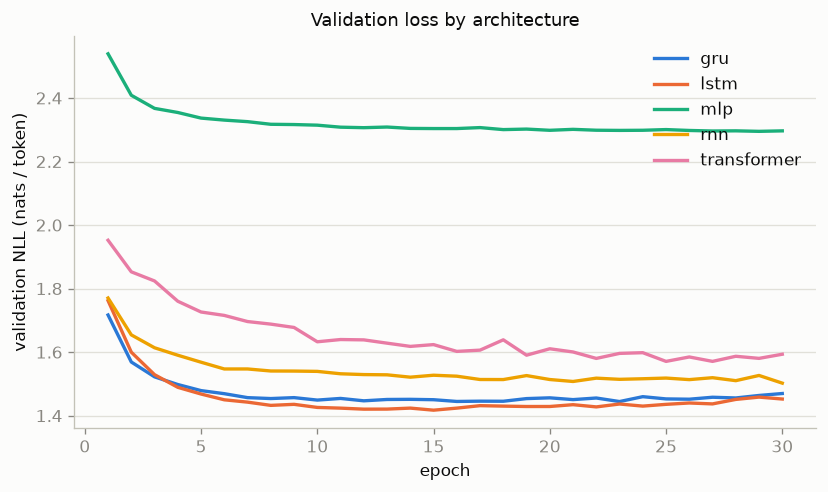

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.2))
for i, r in enumerate(sorted(architectures, key=lambda r: r["run"])):
    h = r["history"]
    ax.plot(h["epoch"], h["val_nll"], lw=2, color=PALETTE[i % len(PALETTE)], label=r["run"])
ax.set_xlabel("epoch")
ax.set_ylabel("validation NLL (nats / token)")
ax.set_title("Validation loss by architecture")
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

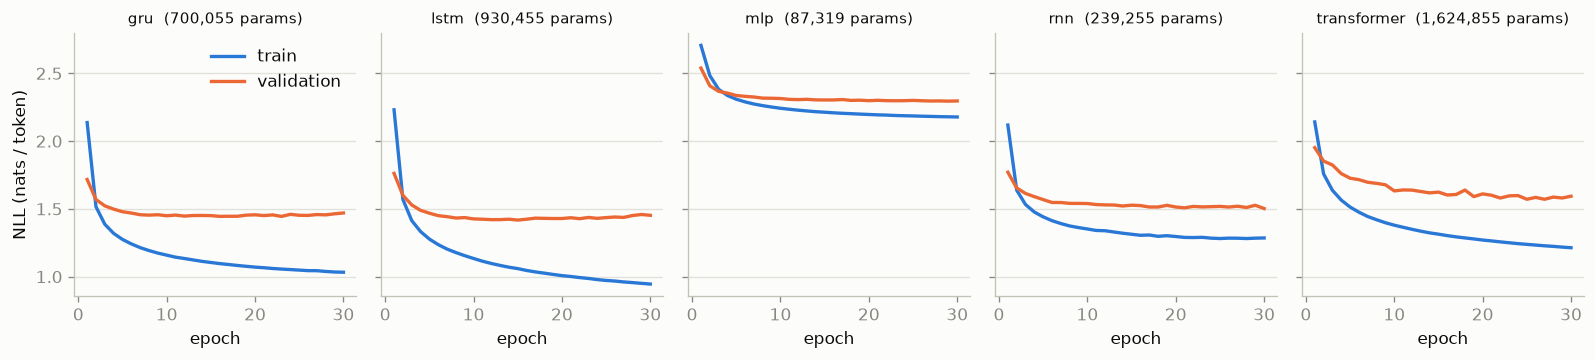

In [17]:
# train vs validation per model - the gap is the overfitting
shown = sorted(architectures, key=lambda r: r["run"])
fig, axes = plt.subplots(1, len(shown), figsize=(2.7 * len(shown), 3.1), sharey=True)
axes = np.atleast_1d(axes)
for ax, r in zip(axes, shown):
    h = r["history"]
    ax.plot(h["epoch"], h["train_nll"], lw=2, color=PALETTE[0], label="train")
    ax.plot(h["epoch"], h["val_nll"], lw=2, color=PALETTE[1], label="validation")
    ax.set_title(f"{r['run']}  ({r['params']:,} params)", fontsize=9)
    ax.set_xlabel("epoch")
    ax.grid(axis="y")
    ax.set_axisbelow(True)
axes[0].set_ylabel("NLL (nats / token)")
axes[0].legend(loc="upper right")
plt.tight_layout()
plt.show()

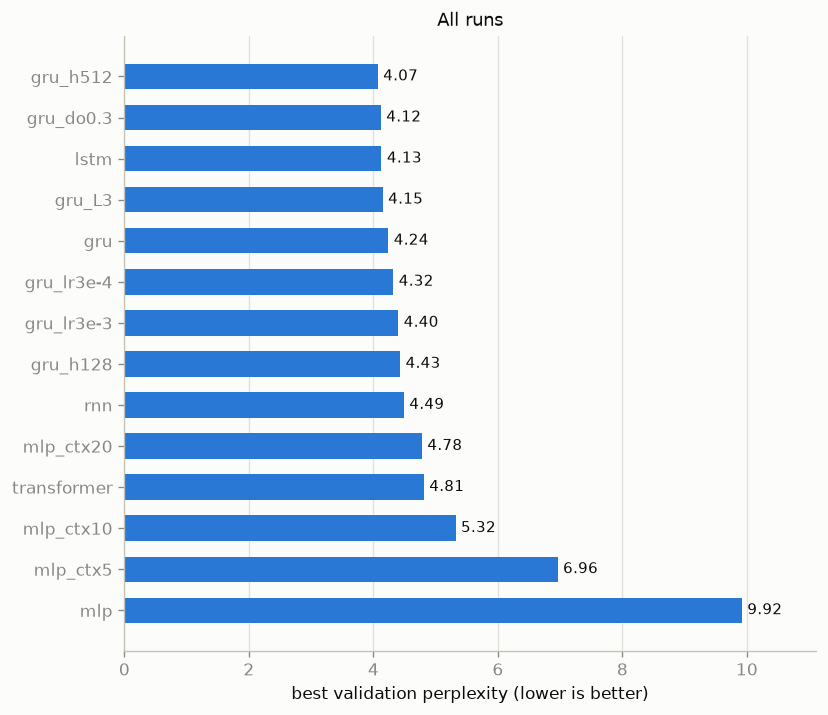

,run,model,params,best_val_nll,best_val_ppl,best_epoch,lr,dropout,hidden_dim,num_layers,context,batch_size,epochs
0,gru_h512,gru,2576791,1.4040,4.07,5,0.0010,0.1,512,2,3,64,30
1,gru_do0.3,gru,700055,1.4151,4.12,29,0.0010,0.3,256,2,3,64,30
2,lstm,lstm,930455,1.4174,4.13,15,0.0010,0.1,256,2,3,64,30
3,gru_L3,gru,1094807,1.4221,4.15,10,0.0010,0.1,256,3,3,64,30
4,gru,gru,700055,1.4445,4.24,23,0.0010,0.1,256,2,3,64,30
5,gru_lr3e-4,gru,700055,1.4632,4.32,28,0.0003,0.1,256,2,3,64,30
6,gru_lr3e-3,gru,700055,1.4807,4.40,6,0.0030,0.1,256,2,3,64,30
7,gru_h128,gru,204055,1.4886,4.43,29,0.0010,0.1,128,2,3,64,30
8,rnn,rnn,239255,1.5024,4.49,30,0.0010,0.1,256,2,3,64,30
9,mlp_ctx20,mlp,174359,1.5640,4.78,30,0.0010,0.1,256,2,20,64,30


In [18]:
all_runs = results_table(results)

fig, ax = plt.subplots(figsize=(7, 0.34 * len(all_runs) + 1.3))
ax.barh(all_runs["run"], all_runs["best_val_ppl"], color=PALETTE[0], height=0.62)
ax.invert_yaxis()
span = all_runs["best_val_ppl"].max() - all_runs["best_val_ppl"].min()
for y, v in zip(all_runs["run"], all_runs["best_val_ppl"]):
    ax.text(v + max(span, 1) * 0.015, y, f"{v:.2f}", va="center", fontsize=9, color=INK)
ax.set_xlabel("best validation perplexity (lower is better)")
ax.set_title("All runs")
ax.set_xlim(0, all_runs["best_val_ppl"].max() * 1.12)
ax.grid(axis="x")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

all_runs

Everything above is validation. The test split stays untouched until the end.

Next: `bsub < hpc/eval.sh`, then `phase1_evaluation_results.ipynb`.